# 04 — Final evaluation and recommendations

**Member 4: Model → Decision → Recommendation**

We evaluate the two Random Forest pipelines already selected using training cross-validation. The main scenario excludes G1/G2; the later-stage comparison includes them and requires both grades to be available. Both use the same 79 held-out students from the 395-student dataset, including recorded G3=0 grades.

This notebook explains each step, reports final MAE, RMSE and R², examines residuals, and assesses the project rule **predicted G3 < 10**. No candidate model, parameter, or threshold is selected from these test results. The saved pipelines are already fitted on the 316 training students: do not fit them again here.

Run all cells from top to bottom in the project's Conda environment. Once inspected, this test set is no longer an unseen resource for further development. Re-running reproduces this evaluation; it does not create a new independent test.

## 1. Setup and artifact checks

Load the exact dataset, split and fitted pipelines used during selection. Fingerprints protect against accidentally evaluating changed data, changed preprocessing, or a different model. Package versions are checked because saved estimators depend on their software environment.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
import importlib.metadata
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    confusion_matrix, precision_score, recall_score, f1_score,
)

PROJECT_ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "data/student-mat.csv").is_file()
    and (folder / "src/preprocessing.py").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import preprocessing  # Needed when joblib restores the shared transformations.

OUTPUT_DIR = PROJECT_ROOT / "docs/evaluation"
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RISK_THRESHOLD = 10  # Project rule; fixed before inspecting predictions.
SCENARIOS = {
    "no_prior_grades": "best_regression_metadata.json",
    "with_prior_grades": "best_with_prior_grades_metadata.json",
}
LABELS = {
    "no_prior_grades": "Main: without G1/G2",
    "with_prior_grades": "Later stage: with G1/G2",
}

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

data_path = PROJECT_ROOT / "data/student-mat.csv"
df = pd.read_csv(data_path, sep=";")
assert len(df) == 395 and df["G3"].between(0, 20).all()
assert df.index.is_unique and int(df["G3"].eq(0).sum()) == 38
metadata, pipelines = {}, {}
for scenario, filename in SCENARIOS.items():
    record = json.loads((PROJECT_ROOT / "models" / filename).read_text(encoding="utf-8"))
    assert record["scenario"] == scenario
    assert sha256(data_path) == record["dataset_sha256"]
    assert sha256(PROJECT_ROOT / "src/preprocessing.py") == record["preprocessing_sha256"]
    pipeline_path = PROJECT_ROOT / record["pipeline_path"]
    assert sha256(pipeline_path) == record["pipeline_sha256"]
    for package, expected in record["versions"].items():
        actual = platform.python_version() if package == "python" else importlib.metadata.version(package)
        assert actual == expected, f"Version mismatch for {package}: {actual} != {expected}"
    train_ids, test_ids = record["training_indices"], record["test_indices"]
    assert len(train_ids) == len(set(train_ids)) == 316
    assert len(test_ids) == len(set(test_ids)) == 79
    assert not set(train_ids) & set(test_ids)
    assert set(train_ids) | set(test_ids) == set(df.index)
    features = record["input_features"]
    assert "G3" not in features
    assert ("G1" in features and "G2" in features) == (scenario == "with_prior_grades")
    metadata[scenario] = record
    pipelines[scenario] = joblib.load(pipeline_path)

main_metadata = metadata["no_prior_grades"]
assert metadata["with_prior_grades"]["training_indices"] == main_metadata["training_indices"]
assert metadata["with_prior_grades"]["test_indices"] == main_metadata["test_indices"]
train_ids, test_ids = main_metadata["training_indices"], main_metadata["test_indices"]
y_train = df.loc[train_ids, "G3"]
y_test = df.loc[test_ids, "G3"]
display(pd.DataFrame([
    {"Split": name, "Students": len(y), "G3 = 0": int(y.eq(0).sum()),
     "G3 < 10": int(y.lt(RISK_THRESHOLD).sum()), "Mean G3": y.mean()}
    for name, y in [("Training", y_train), ("Held-out test", y_test)]
]).round(3))
print("Data, code, versions, model fingerprints and split checks passed.")

           Split  Students  G3 = 0  G3 < 10  Mean G3
0       Training       316      33      103   10.326
1  Held-out test        79       5       27   10.772
Data, code, versions, model fingerprints and split checks passed.


## 2. Predict once and compare with simple benchmarks

**MAE** is the average absolute error in grade points (primary metric). **RMSE** gives larger errors more weight. **R²** compares squared error with predicting the test-set mean: 1 is perfect, 0 matches that reference, and negative values are worse. This reference is a metric definition, not a baseline trained on test labels.

Our practical mean and median baselines use **training labels only**. The later-stage scenario also has a transparent benchmark: use G2 unchanged as the predicted G3. This requires no fitted parameters and helps judge whether the extra model complexity adds value. Predictions stay continuous; we do not round or clip them after seeing results.

In [2]:
def regression_scores(actual, predicted):
    return {
        "MAE": float(mean_absolute_error(actual, predicted)),
        "RMSE": float(root_mean_squared_error(actual, predicted)),
        "R2": float(r2_score(actual, predicted)),
    }

predictions = {}
for scenario in SCENARIOS:
    X_test = df.loc[test_ids, metadata[scenario]["input_features"]].copy()
    assert X_test.index.equals(y_test.index)
    predicted = np.asarray(pipelines[scenario].predict(X_test), dtype=float)
    assert predicted.shape == (79,) and np.isfinite(predicted).all()
    predictions[scenario] = predicted

baseline_predictions = {
    "Training mean baseline": np.full(len(y_test), y_train.mean()),
    "Training median baseline": np.full(len(y_test), y_train.median()),
    "G2 unchanged (later stage only)": df.loc[test_ids, "G2"].to_numpy(dtype=float),
}
all_predictions = {**baseline_predictions, **{LABELS[s]: p for s, p in predictions.items()}}
test_scores = pd.DataFrame({name: regression_scores(y_test, p) for name, p in all_predictions.items()}).T
test_scores.index.name = "Predictor"
display(test_scores.round(4))

cv_test_comparison = pd.DataFrame([
    {"Scenario": LABELS[s], "Metric": metric,
     "Selection CV mean": metadata[s]["selection_cv_scores"][metric],
     "Held-out test": test_scores.loc[LABELS[s], metric]}
    for s in SCENARIOS for metric in ["MAE", "RMSE", "R2"]
])
display(cv_test_comparison.round(4))
print("CV informed model selection; test results assess the frozen choices. The samples and fitting sizes differ.")

,MAE,RMSE,R2
Predictor,,,
Training mean baseline,3.6459,4.5502,-0.0097
Training median baseline,3.6203,4.5340,-0.0025
G2 unchanged (later stage only),1.0000,2.0715,0.7907
Main: without G1/G2,3.0951,3.8714,0.2691
Later stage: with G1/G2,1.1699,1.9749,0.8098


,Scenario,Metric,Selection CV mean,Held-out test
0,Main: without G1/G2,MAE,2.9641,3.0951
1,Main: without G1/G2,RMSE,3.9366,3.8714
2,Main: without G1/G2,R2,0.2081,0.2691
3,Later stage: with G1/G2,MAE,0.9381,1.1699
4,Later stage: with G1/G2,RMSE,1.4757,1.9749
5,Later stage: with G1/G2,R2,0.8928,0.8098


CV informed model selection; test results assess the frozen choices. The samples and fitting sizes differ.


## 3. Residuals and prediction errors

Residual = actual G3 − predicted G3. A negative residual means the model overpredicted the grade, which can hide a student who needs help. Look for systematic errors at low/high grades, a broad error spread, and large individual misses. A near-zero average residual alone does not establish reliability.

,Mean residual,Median absolute error,90th percentile absolute error,Maximum absolute error,Within 2 grade points (%),"Predictions outside [0, 20]"
Scenario,,,,,,
Main: without G1/G2,-0.133,2.414,6.136,11.148,37.975,0
Later stage: with G1/G2,0.022,0.693,2.144,7.621,88.608,0


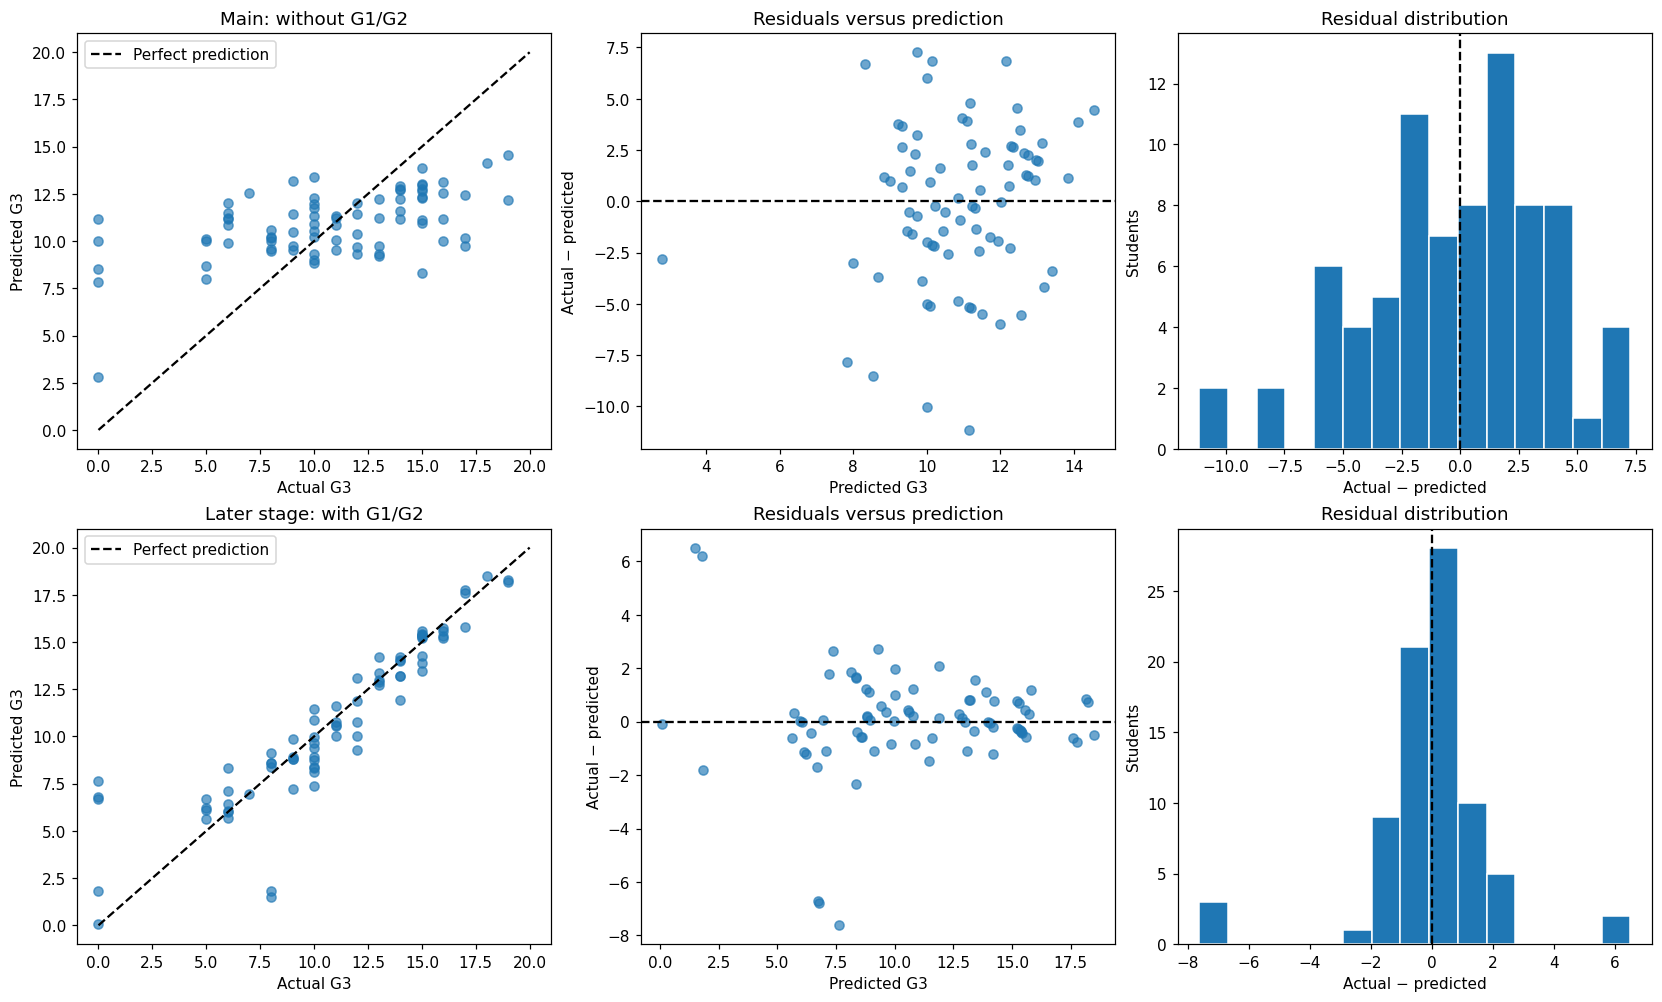

In [3]:
prediction_tables = {}
error_rows = []
for scenario, predicted in predictions.items():
    table = pd.DataFrame({
        "dataset_row_id": test_ids,
        "actual_G3": y_test.to_numpy(),
        "predicted_G3": predicted,
    })
    table["residual"] = table["actual_G3"] - table["predicted_G3"]
    table["absolute_error"] = table["residual"].abs()
    table["actual_at_risk"] = table["actual_G3"].lt(RISK_THRESHOLD)
    table["predicted_at_risk"] = table["predicted_G3"].lt(RISK_THRESHOLD)
    table["flag_outcome"] = np.select(
        [table.actual_at_risk & table.predicted_at_risk,
         table.actual_at_risk & ~table.predicted_at_risk,
         ~table.actual_at_risk & table.predicted_at_risk],
        ["True positive", "False negative", "False positive"], default="True negative",
    )
    prediction_tables[scenario] = table
    error_rows.append({
        "Scenario": LABELS[scenario], "Mean residual": table.residual.mean(),
        "Median absolute error": table.absolute_error.median(),
        "90th percentile absolute error": table.absolute_error.quantile(.9),
        "Maximum absolute error": table.absolute_error.max(),
        "Within 2 grade points (%)": table.absolute_error.le(2).mean() * 100,
        "Predictions outside [0, 20]": int(((predicted < 0) | (predicted > 20)).sum()),
    })
display(pd.DataFrame(error_rows).set_index("Scenario").round(3))

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for row, scenario in enumerate(SCENARIOS):
    table = prediction_tables[scenario]
    ax = axes[row, 0]
    ax.scatter(table.actual_G3, table.predicted_G3, alpha=.65)
    ax.plot([0, 20], [0, 20], "k--", label="Perfect prediction")
    ax.set(xlabel="Actual G3", ylabel="Predicted G3", title=LABELS[scenario])
    ax.legend()
    ax = axes[row, 1]
    ax.scatter(table.predicted_G3, table.residual, alpha=.65)
    ax.axhline(0, color="black", linestyle="--")
    ax.set(xlabel="Predicted G3", ylabel="Actual − predicted", title="Residuals versus prediction")
    ax = axes[row, 2]
    ax.hist(table.residual, bins=15, edgecolor="white")
    ax.axvline(0, color="black", linestyle="--")
    ax.set(xlabel="Actual − predicted", ylabel="Students", title="Residual distribution")
fig.savefig(FIGURE_DIR / "residual_analysis.png", dpi=150)
plt.show()

### Where are errors concentrated?

These groups use the **observed final grade** for retrospective diagnosis. They are not inputs or rules available before G3 is known. Retain zero-grade students in the headline results; report their errors separately because their causes remain unknown. Small group counts make estimates unstable. The largest-error tables are for auditing, not naming or penalizing students.

In [4]:
grade_error_rows = []
for scenario, table in prediction_tables.items():
    groups = {
        "G3 = 0": table.actual_G3.eq(0),
        "G3 = 1–9": table.actual_G3.between(1, 9),
        "G3 = 10–14": table.actual_G3.between(10, 14),
        "G3 = 15–20": table.actual_G3.between(15, 20),
    }
    for name, mask in groups.items():
        subset = table.loc[mask]
        grade_error_rows.append({
            "Scenario": LABELS[scenario], "Observed grade group": name, "Students": len(subset),
            "MAE": subset.absolute_error.mean(), "Mean residual": subset.residual.mean(),
        })
    display(Markdown(f"**{LABELS[scenario]}: ten largest errors**"))
    display(table.nlargest(10, "absolute_error").round(3))
grade_errors = pd.DataFrame(grade_error_rows)
display(grade_errors.round(3))

**Main: without G1/G2: ten largest errors**

,dataset_row_id,actual_G3,predicted_G3,residual,absolute_error,actual_at_risk,predicted_at_risk,flag_outcome
24,140,0,11.148,-11.148,11.148,True,False,False negative
8,316,0,10.021,-10.021,10.021,True,False,False negative
57,168,0,8.530,-8.530,8.530,True,True,True positive
19,334,0,7.841,-7.841,7.841,True,True,True positive
65,182,17,9.730,7.270,7.270,False,True,False positive
28,101,17,10.147,6.853,6.853,False,False,True negative
25,113,19,12.155,6.845,6.845,False,False,True negative
18,324,15,8.323,6.677,6.677,False,True,False positive
63,177,6,12.001,-6.001,6.001,True,False,False negative
22,167,16,10.006,5.994,5.994,False,False,True negative


**Later stage: with G1/G2: ten largest errors**

,dataset_row_id,actual_G3,predicted_G3,residual,absolute_error,actual_at_risk,predicted_at_risk,flag_outcome
24,140,0,7.621,-7.621,7.621,True,True,True positive
19,334,0,6.787,-6.787,6.787,True,True,True positive
8,316,0,6.713,-6.713,6.713,True,True,True positive
34,90,8,1.488,6.512,6.512,True,True,True positive
16,124,8,1.792,6.208,6.208,True,True,True positive
27,33,12,9.275,2.725,2.725,False,True,False positive
45,93,10,7.355,2.645,2.645,False,True,False positive
70,45,6,8.342,-2.342,2.342,True,True,True positive
38,73,14,11.905,2.095,2.095,False,False,True negative
52,30,12,10.013,1.987,1.987,False,False,True negative


,Scenario,Observed grade group,Students,MAE,Mean residual
0,Main: without G1/G2,G3 = 0,5,8.071,-8.071
1,Main: without G1/G2,G3 = 1–9,22,3.376,-3.376
2,Main: without G1/G2,G3 = 10–14,32,1.538,0.732
3,Main: without G1/G2,G3 = 15–20,20,4.034,4.034
4,Later stage: with G1/G2,G3 = 0,5,4.606,-4.606
5,Later stage: with G1/G2,G3 = 1–9,22,1.245,0.152
6,Later stage: with G1/G2,G3 = 10–14,32,0.912,0.548
7,Later stage: with G1/G2,G3 = 15–20,20,0.641,0.194


## 4. Does the grade-10 risk flag find the right students?

The positive class is observed **G3 < 10**. Apply the same strict inequality to continuous predictions; predicted 10 is not flagged.

- **Recall:** fraction of truly at-risk students flagged. False negatives are at-risk students the rule misses.
- **Precision:** fraction of flagged students actually below 10. False positives can create unnecessary concern or use support capacity.
- **Specificity:** fraction of students with G3 ≥ 10 correctly left unflagged.
- **F1:** balances precision and recall; it does not encode the school's costs of missed support versus unnecessary review.

Regression accuracy does not guarantee a useful flag. We also show flag-all and flag-none references to expose the tradeoff. The fixed threshold is evaluated here, not optimized on the test set. Undefined rates are reported as missing rather than as evidence of good performance.

,Students,Actual at risk,Flagged,TP,FP,FN,TN,Precision,Recall,Specificity,F1
Rule,,,,,,,,,,,
Training mean baseline,79.0,27.0,0.0,0.0,0.0,27.0,52.0,NaN,0.000,1.000,0.000
Training median baseline,79.0,27.0,0.0,0.0,0.0,27.0,52.0,NaN,0.000,1.000,0.000
G2 unchanged (later stage only),79.0,27.0,32.0,26.0,6.0,1.0,46.0,0.812,0.963,0.885,0.881
Main: without G1/G2,79.0,27.0,21.0,10.0,11.0,17.0,41.0,0.476,0.370,0.788,0.417
Later stage: with G1/G2,79.0,27.0,37.0,27.0,10.0,0.0,42.0,0.730,1.000,0.808,0.844
Flag every student,79.0,27.0,79.0,27.0,52.0,0.0,0.0,0.342,1.000,0.000,0.509
Flag no students,79.0,27.0,0.0,0.0,0.0,27.0,52.0,NaN,0.000,1.000,0.000


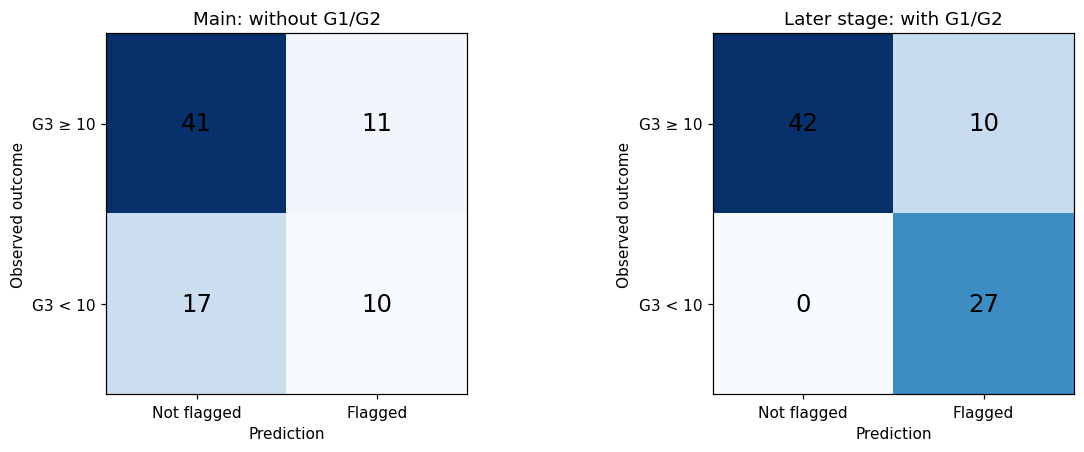

**Main: without G1/G2: flagged students (dataset row IDs)**

,dataset_row_id,actual_G3,predicted_G3,residual,absolute_error,actual_at_risk,predicted_at_risk,flag_outcome
36,137,0,2.815,-2.815,2.815,True,True,True positive
19,334,0,7.841,-7.841,7.841,True,True,True positive
40,72,5,8.007,-3.007,3.007,True,True,True positive
18,324,15,8.323,6.677,6.677,False,True,False positive
57,168,0,8.530,-8.530,8.530,True,True,True positive
78,18,5,8.668,-3.668,3.668,True,True,True positive
62,157,10,8.838,1.162,1.162,False,True,False positive
0,78,10,9.003,0.997,0.997,False,True,False positive
5,223,13,9.211,3.789,3.789,False,True,False positive
13,393,10,9.321,0.679,0.679,False,True,False positive


**Main: without G1/G2: missed at-risk students**

,dataset_row_id,actual_G3,predicted_G3,residual,absolute_error,actual_at_risk,predicted_at_risk,flag_outcome
24,140,0,11.148,-11.148,11.148,True,False,False negative
8,316,0,10.021,-10.021,10.021,True,False,False negative
63,177,6,12.001,-6.001,6.001,True,False,False negative
11,209,7,12.559,-5.559,5.559,True,False,False negative
75,82,6,11.511,-5.511,5.511,True,False,False negative
7,234,6,11.216,-5.216,5.216,True,False,False negative
54,386,6,11.154,-5.154,5.154,True,False,False negative
2,248,5,10.087,-5.087,5.087,True,False,False negative
35,384,5,10.003,-5.003,5.003,True,False,False negative
70,45,6,10.862,-4.862,4.862,True,False,False negative


**Later stage: with G1/G2: flagged students (dataset row IDs)**

,dataset_row_id,actual_G3,predicted_G3,residual,absolute_error,actual_at_risk,predicted_at_risk,flag_outcome
36,137,0,0.093,-0.093,0.093,True,True,True positive
34,90,8,1.488,6.512,6.512,True,True,True positive
16,124,8,1.792,6.208,6.208,True,True,True positive
57,168,0,1.816,-1.816,1.816,True,True,True positive
78,18,5,5.618,-0.618,0.618,True,True,True positive
54,386,6,5.683,0.317,0.317,True,True,True positive
75,82,6,5.977,0.023,0.023,True,True,True positive
63,177,6,6.026,-0.026,0.026,True,True,True positive
35,384,5,6.123,-1.123,1.123,True,True,True positive
2,248,5,6.203,-1.203,1.203,True,True,True positive


**Later stage: with G1/G2: missed at-risk students**

,dataset_row_id,actual_G3,predicted_G3,residual,absolute_error,actual_at_risk,predicted_at_risk,flag_outcome


In [5]:
actual_risk = y_test.lt(RISK_THRESHOLD).to_numpy()

def risk_scores(actual, flagged):
    tn, fp, fn, tp = confusion_matrix(actual, flagged, labels=[False, True]).ravel()
    return {
        "Students": len(actual), "Actual at risk": int(tp + fn), "Flagged": int(tp + fp),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "Precision": float(precision_score(actual, flagged, zero_division=np.nan)),
        "Recall": float(recall_score(actual, flagged, zero_division=np.nan)),
        "Specificity": float(tn / (tn + fp)) if tn + fp else np.nan,
        "F1": float(f1_score(actual, flagged, zero_division=np.nan)),
    }

risk_rows = {name: risk_scores(actual_risk, p < RISK_THRESHOLD) for name, p in all_predictions.items()}
risk_rows["Flag every student"] = risk_scores(actual_risk, np.ones(len(y_test), dtype=bool))
risk_rows["Flag no students"] = risk_scores(actual_risk, np.zeros(len(y_test), dtype=bool))
risk_results = pd.DataFrame(risk_rows).T
risk_results.index.name = "Rule"
display(risk_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for ax, scenario in zip(axes, SCENARIOS):
    cm = confusion_matrix(actual_risk, predictions[scenario] < RISK_THRESHOLD, labels=[False, True])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=16)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Not flagged", "Flagged"],
           yticklabels=["G3 ≥ 10", "G3 < 10"], xlabel="Prediction", ylabel="Observed outcome", title=LABELS[scenario])
fig.savefig(FIGURE_DIR / "risk_confusion_matrices.png", dpi=150)
plt.show()

for scenario, table in prediction_tables.items():
    display(Markdown(f"**{LABELS[scenario]}: flagged students (dataset row IDs)**"))
    display(table.loc[table.predicted_at_risk].sort_values("predicted_G3").round(3))
    display(Markdown(f"**{LABELS[scenario]}: missed at-risk students**"))
    display(table.loc[table.flag_outcome.eq("False negative")].sort_values("absolute_error", ascending=False).round(3))

## 5. Descriptive group checks

Check error and flag recall by recorded sex and school to look for possible uneven performance. These small test groups cannot establish fairness or prove discrimination; absence of a visible difference is not proof of fairness. No model or threshold is changed using these checks. A future deployment needs a larger representative audit and review of whether each personal attribute is appropriate.

In [6]:
group_rows = []
for scenario, table in prediction_tables.items():
    audit = table.set_index("dataset_row_id").join(df.loc[test_ids, ["sex", "school"]])
    for attribute in ["sex", "school"]:
        for value, subset in audit.groupby(attribute):
            rates = risk_scores(subset.actual_at_risk.to_numpy(), subset.predicted_at_risk.to_numpy())
            group_rows.append({"Scenario": LABELS[scenario], "Attribute": attribute, "Group": value,
                "Students": len(subset), "Actual at risk": rates["Actual at risk"],
                "MAE": subset.absolute_error.mean(), "Recall": rates["Recall"],
                "Precision": rates["Precision"], "Missed at risk": rates["FN"]})
group_audit = pd.DataFrame(group_rows)
display(group_audit.round(3))

,Scenario,Attribute,Group,Students,Actual at risk,MAE,Recall,Precision,Missed at risk
0,Main: without G1/G2,sex,F,38,15,3.148,0.467,0.538,8
1,Main: without G1/G2,sex,M,41,12,3.046,0.250,0.375,9
2,Main: without G1/G2,school,GP,67,23,3.243,0.391,0.529,14
3,Main: without G1/G2,school,MS,12,4,2.271,0.250,0.250,3
4,Later stage: with G1/G2,sex,F,38,15,1.398,1.000,0.714,0
5,Later stage: with G1/G2,sex,M,41,12,0.959,1.000,0.750,0
6,Later stage: with G1/G2,school,GP,67,23,1.228,1.000,0.767,0
7,Later stage: with G1/G2,school,MS,12,4,0.844,1.000,0.571,0


## 6. Findings, recommendations and limitations

The next cell writes a summary from the calculated results so the report stays consistent with the tables. Recommendations concern supportive review. This observational experiment does not show that changing an input feature causes a better grade.

In [7]:
main = test_scores.loc[LABELS["no_prior_grades"]]
later = test_scores.loc[LABELS["with_prior_grades"]]
main_risk = risk_results.loc[LABELS["no_prior_grades"]]
later_risk = risk_results.loc[LABELS["with_prior_grades"]]
median_mae = test_scores.loc["Training median baseline", "MAE"]
g2_mae = test_scores.loc["G2 unchanged (later stage only)", "MAE"]
main_improvement = (median_mae - main.MAE) / median_mae * 100
g2_comparison = "lower" if later.MAE < g2_mae else "higher"
g2_risk = risk_results.loc["G2 unchanged (later stage only)"]
zero_errors = grade_errors.loc[grade_errors["Observed grade group"].eq("G3 = 0")]
zero_text = "; ".join(f"{row['Scenario']}: MAE {row['MAE']:.3f} across {int(row['Students'])} students"
                      for _, row in zero_errors.iterrows())

report = f"""# Final evaluation and recommendations

## Evidence from the held-out set

Both frozen Random Forest models were evaluated on the same {len(y_test)} students; {int(actual_risk.sum())} had G3 < 10. Model choice and tuning used only the 316 training students. All 395 students, including 38 recorded zero grades, remain in scope.

- **Main model, without G1/G2:** MAE **{main.MAE:.3f}**, RMSE **{main.RMSE:.3f}**, R² **{main.R2:.3f}**. Relative MAE reduction versus the training-median baseline is **{main_improvement:.1f}%** (negative means worse). An MAE is an average, not a guarantee for an individual student.
- **Later-stage model, with G1/G2:** MAE **{later.MAE:.3f}**, RMSE **{later.RMSE:.3f}**, R² **{later.R2:.3f}**. Its MAE is {g2_comparison} than the simple G2-unchanged benchmark (**{g2_mae:.3f}**). These inputs require a later prediction time; this is a separate scenario, not an early-warning accuracy claim.
- **Main risk rule (predicted G3 < 10):** flags **{int(main_risk.Flagged)}** students, correctly flags **{int(main_risk.TP)}**, misses **{int(main_risk.FN)}** at-risk students, and produces **{int(main_risk.FP)}** false positives. Precision is **{main_risk.Precision:.1%}** and recall is **{main_risk.Recall:.1%}**.
- **Later-stage risk rule:** flags **{int(later_risk.Flagged)}**, correctly flags **{int(later_risk.TP)}**, misses **{int(later_risk.FN)}**, and produces **{int(later_risk.FP)}** false positives. Precision is **{later_risk.Precision:.1%}** and recall is **{later_risk.Recall:.1%}**.
- **Recorded zero-grade errors:** {zero_text}. These observations are retained, and their causes are not established by this dataset.

### Error patterns and simple alternatives

The main-model grade-group table shows overprediction at the low end (negative mean residuals for G3=0 and G3=1–9) and underprediction at the high end (positive mean residual for G3=15–20). Predictions tend toward the middle of the observed range. This helps explain why many students below 10 are missed despite improvement over a constant baseline. The later-stage model still has large errors among the five zero-grade test students.

Simply flagging G2 < 10 misses **{int(g2_risk.FN)}** at-risk student(s) and produces **{int(g2_risk.FP)}** false positives. The later-stage forest catches **{int(later_risk.TP - g2_risk.TP)}** additional at-risk student(s) with **{int(later_risk.FP - g2_risk.FP)}** additional false positives. It also has worse MAE than using G2 unchanged, although its RMSE is lower. It is therefore not an unqualified improvement over that simple reference. This comparison does not retrospectively replace the frozen model selection. Perfect observed recall in a small sample does not guarantee perfect recall on future students.

The descriptive audit shows different main-model recall across recorded sex groups and schools. Counts are small, especially the 12-student MS group with four observed at-risk students; investigate these signals using larger representative data before drawing conclusions.

## Practical recommendations

1. Use the main model only as an exploratory support signal. Its {int(main_risk.FN)} missed at-risk students mean an unflagged prediction must not exclude a student from assistance. Combine teacher observations, student requests and academic evidence with model flags.
2. For flagged students, have a staff member check current performance and data accuracy, speak with the student, and agree on appropriate support such as tutoring, study planning or attendance assistance. A predicted low grade is not a diagnosis or evidence of lack of effort.
3. If G1 and G2 are available, consider the later-stage scenario for follow-up after the second grading period. Compare its value with simply reviewing G2, including support workload and missed students, before adopting a complex model.
4. Keep the grade-10 rule fixed for this report. If a school needs greater recall or a different review workload, choose a new operating rule using training/validation data and a stated cost tradeoff, then evaluate it on new untouched data. Do not tune on these 79 test outcomes.
5. Before practical use, define a prediction date and verify every input is available then, particularly absences. Run a prospective pilot on a new cohort, check subgroup performance with adequate sample sizes, and monitor missed support cases and unnecessary reviews. Keep access limited to authorized support staff and allow students to correct inaccurate data.

## Limitations and responsible use

- The dataset has only 395 Mathematics students from two schools. One 79-student random holdout does not establish performance in other subjects, schools or future cohorts; a new temporal or external evaluation is needed.
- The full dataset was explored during EDA before splitting, so the holdout was not fully blind to exploratory analysis. Training CV scores also informed model selection and are not independent estimates of final performance.
- Input availability remains unresolved. Excluding G1/G2 alone does not prove that the main model can be used early; whole-period absences or other later-collected inputs could be unavailable at the intended date.
- Recorded zero grades are valid observations for this analysis, but their meaning is unknown. The model cannot distinguish their causes or justify relabeling them.
- Subgroup checks are descriptive and small; they do not establish fairness. Personal and family attributes require an appropriateness and privacy review before operational use.
- Regression outputs are point estimates, not probabilities or individual uncertainty intervals. Error averages and a fixed threshold cannot ensure reliable decisions near grade 10.
- Associations and prediction accuracy do not demonstrate that a particular intervention will improve grades. Assess support outcomes separately.
- No automatic disciplinary action, exclusion, grading decision or denial of support should follow a model prediction. Staff should review context, communicate uncertainty and retain responsibility.

## Conclusion

The final test results quantify both grade error and the consequences of the risk flag. Treat this as an educational modelling study and a candidate for a supervised support pilot, not a validated automatic decision system. Preserve these results as the final evaluation of the frozen models; further development needs new evaluation data.
"""
display(Markdown(report))

# Final evaluation and recommendations

## Evidence from the held-out set

Both frozen Random Forest models were evaluated on the same 79 students; 27 had G3 < 10. Model choice and tuning used only the 316 training students. All 395 students, including 38 recorded zero grades, remain in scope.

- **Main model, without G1/G2:** MAE **3.095**, RMSE **3.871**, R² **0.269**. Relative MAE reduction versus the training-median baseline is **14.5%** (negative means worse). An MAE is an average, not a guarantee for an individual student.
- **Later-stage model, with G1/G2:** MAE **1.170**, RMSE **1.975**, R² **0.810**. Its MAE is higher than the simple G2-unchanged benchmark (**1.000**). These inputs require a later prediction time; this is a separate scenario, not an early-warning accuracy claim.
- **Main risk rule (predicted G3 < 10):** flags **21** students, correctly flags **10**, misses **17** at-risk students, and produces **11** false positives. Precision is **47.6%** and recall is **37.0%**.
- **Later-stage risk rule:** flags **37**, correctly flags **27**, misses **0**, and produces **10** false positives. Precision is **73.0%** and recall is **100.0%**.
- **Recorded zero-grade errors:** Main: without G1/G2: MAE 8.071 across 5 students; Later stage: with G1/G2: MAE 4.606 across 5 students. These observations are retained, and their causes are not established by this dataset.

### Error patterns and simple alternatives

The main-model grade-group table shows overprediction at the low end (negative mean residuals for G3=0 and G3=1–9) and underprediction at the high end (positive mean residual for G3=15–20). Predictions tend toward the middle of the observed range. This helps explain why many students below 10 are missed despite improvement over a constant baseline. The later-stage model still has large errors among the five zero-grade test students.

Simply flagging G2 < 10 misses **1** at-risk student(s) and produces **6** false positives. The later-stage forest catches **1** additional at-risk student(s) with **4** additional false positives. It also has worse MAE than using G2 unchanged, although its RMSE is lower. It is therefore not an unqualified improvement over that simple reference. This comparison does not retrospectively replace the frozen model selection. Perfect observed recall in a small sample does not guarantee perfect recall on future students.

The descriptive audit shows different main-model recall across recorded sex groups and schools. Counts are small, especially the 12-student MS group with four observed at-risk students; investigate these signals using larger representative data before drawing conclusions.

## Practical recommendations

1. Use the main model only as an exploratory support signal. Its 17 missed at-risk students mean an unflagged prediction must not exclude a student from assistance. Combine teacher observations, student requests and academic evidence with model flags.
2. For flagged students, have a staff member check current performance and data accuracy, speak with the student, and agree on appropriate support such as tutoring, study planning or attendance assistance. A predicted low grade is not a diagnosis or evidence of lack of effort.
3. If G1 and G2 are available, consider the later-stage scenario for follow-up after the second grading period. Compare its value with simply reviewing G2, including support workload and missed students, before adopting a complex model.
4. Keep the grade-10 rule fixed for this report. If a school needs greater recall or a different review workload, choose a new operating rule using training/validation data and a stated cost tradeoff, then evaluate it on new untouched data. Do not tune on these 79 test outcomes.
5. Before practical use, define a prediction date and verify every input is available then, particularly absences. Run a prospective pilot on a new cohort, check subgroup performance with adequate sample sizes, and monitor missed support cases and unnecessary reviews. Keep access limited to authorized support staff and allow students to correct inaccurate data.

## Limitations and responsible use

- The dataset has only 395 Mathematics students from two schools. One 79-student random holdout does not establish performance in other subjects, schools or future cohorts; a new temporal or external evaluation is needed.
- The full dataset was explored during EDA before splitting, so the holdout was not fully blind to exploratory analysis. Training CV scores also informed model selection and are not independent estimates of final performance.
- Input availability remains unresolved. Excluding G1/G2 alone does not prove that the main model can be used early; whole-period absences or other later-collected inputs could be unavailable at the intended date.
- Recorded zero grades are valid observations for this analysis, but their meaning is unknown. The model cannot distinguish their causes or justify relabeling them.
- Subgroup checks are descriptive and small; they do not establish fairness. Personal and family attributes require an appropriateness and privacy review before operational use.
- Regression outputs are point estimates, not probabilities or individual uncertainty intervals. Error averages and a fixed threshold cannot ensure reliable decisions near grade 10.
- Associations and prediction accuracy do not demonstrate that a particular intervention will improve grades. Assess support outcomes separately.
- No automatic disciplinary action, exclusion, grading decision or denial of support should follow a model prediction. Staff should review context, communicate uncertainty and retain responsibility.

## Conclusion

The final test results quantify both grade error and the consequences of the risk flag. Treat this as an educational modelling study and a candidate for a supervised support pilot, not a validated automatic decision system. Preserve these results as the final evaluation of the frozen models; further development needs new evaluation data.


## 7. Export reproducible evaluation evidence

Save the report, metric tables, complete held-out predictions, flagged rows, missed cases, group checks and figures under `docs/evaluation/`. Dataset row IDs refer to the unchanged CSV index; they are not real student identifiers. Flag lists are retrospective test-set evidence, not a live roster. Labels and residuals would not be available for future students.

The evaluation manifest links results to the selected artifacts. Selection metadata and training experiment records remain the historical handoff; this manifest records that final test evaluation has now occurred.

In [8]:
test_scores.to_csv(OUTPUT_DIR / "test_regression_metrics.csv")
pd.DataFrame(error_rows).to_csv(OUTPUT_DIR / "test_error_summary.csv", index=False)
cv_test_comparison.to_csv(OUTPUT_DIR / "cv_test_comparison.csv", index=False)
risk_results.to_csv(OUTPUT_DIR / "test_risk_metrics.csv")
grade_errors.to_csv(OUTPUT_DIR / "errors_by_observed_grade.csv", index=False)
group_audit.to_csv(OUTPUT_DIR / "descriptive_group_audit.csv", index=False)
for scenario, table in prediction_tables.items():
    table.to_csv(OUTPUT_DIR / f"{scenario}_test_predictions.csv", index=False)
    table.loc[table.predicted_at_risk].sort_values("predicted_G3").to_csv(
        OUTPUT_DIR / f"{scenario}_flagged_students.csv", index=False)
    table.loc[table.flag_outcome.eq("False negative")].to_csv(
        OUTPUT_DIR / f"{scenario}_missed_at_risk.csv", index=False)

(OUTPUT_DIR / "final_evaluation_recommendations.md").write_text(report, encoding="utf-8")
manifest = {
    "evaluated_at_utc": datetime.now(timezone.utc).isoformat(),
    "notebook": "notebooks/04_evaluation_recommendations.ipynb",
    "test_performance_evaluated": True,
    "test_indices": test_ids,
    "training_indices": train_ids,
    "dataset_sha256": sha256(data_path),
    "preprocessing_sha256": sha256(PROJECT_ROOT / "src/preprocessing.py"),
    "versions": main_metadata["versions"],
    "risk_threshold": RISK_THRESHOLD,
    "risk_rule": "predicted_G3 < 10 (continuous, unrounded)",
    "refitted_or_retuned_on_test": False,
    "scenarios": {
        s: {"model": metadata[s]["model"], "pipeline_path": metadata[s]["pipeline_path"],
            "pipeline_sha256": metadata[s]["pipeline_sha256"],
            "regression_metrics": regression_scores(y_test, predictions[s]),
            "risk_metrics": risk_scores(actual_risk, predictions[s] < RISK_THRESHOLD)}
        for s in SCENARIOS
    },
}
assert all(np.isfinite(v) for s in manifest["scenarios"].values() for v in s["regression_metrics"].values())
(OUTPUT_DIR / "evaluation_manifest.json").write_text(json.dumps(manifest, indent=2, allow_nan=False), encoding="utf-8")
assert all(len(t) == len(test_ids) for t in prediction_tables.values())
assert all(int(risk_results.loc[LABELS[s], ["TP", "FP", "FN", "TN"]].sum()) == len(test_ids) for s in SCENARIOS)
print("Evaluation complete. Reports and evidence saved to:", OUTPUT_DIR)
print("Both saved pipelines were used without refitting or test-based tuning.")

Evaluation complete. Reports and evidence saved to: C:\Projects\EduPredict\docs\evaluation
Both saved pipelines were used without refitting or test-based tuning.
